# Cardiovascular Disease Analysis

**Part 1:** all the original code, grouped into ordered sections.  
**Part 2 (at the end):** a clean short version of the same analysis.

Run order: **Restart, then Run All**. `cardio_train.csv` must be in the same folder as this notebook.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## 1. Load and first look

Load the file and check its size, types, missing values, duplicates and the target balance.

In [2]:
import pandas as pd
df=pd.read_csv("cardio_train.csv")
df.shape

(70000, 13)

In [3]:
df["age"]

0        50
1        55
2        52
3        48
4        48
         ..
69995    53
69996    62
69997    52
69998    61
69999    56
Name: age, Length: 70000, dtype: int64

In [4]:
df

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,2,52,1,165,64.0,130,70,3,1,0,0,0,1
3,3,48,2,169,82.0,150,100,1,1,0,0,1,1
4,4,48,1,156,56.0,100,60,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,99993,53,2,168,76.0,120,80,1,1,1,0,1,0
69996,99995,62,1,158,126.0,140,90,2,2,0,0,1,1
69997,99996,52,2,183,105.0,180,90,3,1,0,1,0,1
69998,99998,61,1,163,72.0,135,80,1,2,0,0,0,1


In [5]:
df["height"]

0        168
1        156
2        165
3        169
4        156
        ... 
69995    168
69996    158
69997    183
69998    163
69999    170
Name: height, Length: 70000, dtype: int64

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [7]:
df.dtypes

id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
dtype: object

In [8]:
df.isnull().sum()

id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["cardio"].value_counts()

cardio
0    35021
1    34979
Name: count, dtype: int64

In [13]:
df.groupby("cardio")["weight"].mean()

cardio
0    71.592150
1    76.822368
Name: weight, dtype: float64

In [14]:
x=df["age"].idxmax()
print(x)

70


In [15]:
df.loc[df["age"].idxmax()]

id              95.0
age             65.0
gender           1.0
height         155.0
weight          57.0
ap_hi          120.0
ap_lo           80.0
cholesterol      1.0
gluc             1.0
smoke            0.0
alco             0.0
active           1.0
cardio           1.0
Name: 70, dtype: float64

In [16]:
df.loc[df["cholesterol"].idxmax()]

id               1.0
age             55.0
gender           1.0
height         156.0
weight          85.0
ap_hi          140.0
ap_lo           90.0
cholesterol      3.0
gluc             1.0
smoke            0.0
alco             0.0
active           1.0
cardio           1.0
Name: 1, dtype: float64

In [17]:
df[["ap_hi", "ap_lo"]].describe()

,ap_hi,ap_lo
count,70000.000000,70000.000000
mean,128.817286,96.630414
std,154.011419,188.472530
min,-150.000000,-70.000000
25%,120.000000,80.000000
50%,120.000000,80.000000
75%,140.000000,90.000000
max,16020.000000,11000.000000


In [18]:
df.groupby("id")["cholesterol"].idxmax()

id
0            0
1            1
2            2
3            3
4            4
         ...  
99993    69995
99995    69996
99996    69997
99998    69998
99999    69999
Name: cholesterol, Length: 70000, dtype: int64

In [19]:
df["age"].value_counts().sort_values(ascending=False).head(10)

age
54    5961
56    5944
58    5693
60    5420
52    5279
50    5242
62    3887
64    3854
48    3167
46    2923
Name: count, dtype: int64

In [20]:
x=df.loc[df["cardio"].max()]
print(x[["cardio","gender"]])

cardio    1.0
gender    1.0
Name: 1, dtype: float64


In [21]:

df["cardio"]

0        0
1        1
2        1
3        1
4        0
        ..
69995    0
69996    1
69997    1
69998    1
69999    0
Name: cardio, Length: 70000, dtype: int64

In [22]:
df.groupby("cardio")["smoke"].count()

cardio
0    35021
1    34979
Name: smoke, dtype: int64

In [23]:
x=df["cardio"].value_counts()[1]
print(x)                         

34979


In [24]:
x=df[(df["cardio"] == 1) & (df["smoke"] == 1)].shape[0]
print("cardio person smoking :",x)

cardio person smoking : 2929


In [25]:
df.groupby("cardio")["smoke"].sum()

cardio
0    3240
1    2929
Name: smoke, dtype: int64

In [26]:
df[(df["cardio"] == 1) & (df["smoke"] == 1)].shape[0]

2929

In [27]:
import plotly.express as px
fig = px.bar(
    df.groupby(["cardio", "smoke"]).size().reset_index(name="count"),
    x="cardio",
    y="count",
    color="smoke",
    barmode="group",
    title="Cardio vs Smoking"
)
fig.update_layout(

)

fig.show()


## 3. Cleaning

Calculate BMI, then remove rows with impossible blood pressure, height, weight or BMI.

In [28]:
x=df["bmi"] = df["weight"] / (df["height"] / 100) ** 2
print(x)

0        21.967120
1        34.927679
2        23.507805
3        28.710479
4        23.011177
           ...    
69995    26.927438
69996    50.472681
69997    31.353579
69998    27.099251
69999    24.913495
Length: 70000, dtype: float64


In [29]:
before = len(df)
df = df[
    (df["ap_hi"].between(60, 250)) &
    (df["ap_lo"].between(40, 200)) &
    (df["ap_hi"] > df["ap_lo"]) &
    (df["height"].between(120, 220)) &
    (df["weight"].between(30, 200)) &
    (df["bmi"].between(12, 60))
].copy()
print(f"Removed {before - len(df)} rows ({(before - len(df)) / before:.1%})")

Removed 1409 rows (2.0%)


In [30]:
df.shape

(68591, 14)

## 4. New columns: labels, age groups, BMI groups

map() turns codes into words, pd.cut() turns numbers into groups.

In [31]:
df["gender_label"] = df["gender"].map({1: "Female", 2: "Male"})
df["cardio_label"] = df["cardio"].map({0: "No Disease", 1: "Disease"})
df["chol_label"] = df["cholesterol"].map({1: "Normal", 2: "Above Normal", 3: "Well Above"})
df["gluc_label"] = df["gluc"].map({1: "Normal", 2: "Above Normal", 3: "Well Above"})

In [32]:
df.shape

(68591, 18)

In [33]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'bmi',
       'gender_label', 'cardio_label', 'chol_label', 'gluc_label'],
      dtype='str')

In [34]:
df["age_group"] = pd.cut(df["age"], bins=[29, 40, 45, 50, 55, 60, 65],
                         labels=["30-40", "41-45", "46-50", "51-55", "56-60", "61-65"])

In [35]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'bmi',
       'gender_label', 'cardio_label', 'chol_label', 'gluc_label',
       'age_group'],
      dtype='str')

In [36]:
df["age"]

0        50
1        55
2        52
3        48
4        48
         ..
69995    53
69996    62
69997    52
69998    61
69999    56
Name: age, Length: 68591, dtype: int64

In [37]:
df["bmi_group"] = pd.cut(df["bmi"], bins=[0, 18.5, 25, 30, 100],
                         labels=["Underweight", "Normal", "Overweight", "Obese"])

In [38]:
df["bmi_group"]

0            Normal
1             Obese
2            Normal
3        Overweight
4            Normal
            ...    
69995    Overweight
69996         Obese
69997         Obese
69998    Overweight
69999        Normal
Name: bmi_group, Length: 68591, dtype: category
Categories (4, str): ['Underweight' < 'Normal' < 'Overweight' < 'Obese']

In [39]:
df["age_group"] = pd.cut(df["age"], bins=[29, 40, 45, 50, 55, 60, 65],
                         labels=["30-40", "41-45", "46-50", "51-55", "56-60", "61-65"])

df["bmi_group"] = pd.cut(df["bmi"], bins=[0, 18.5, 25, 30, 100],
                         labels=["Underweight", "Normal", "Overweight", "Obese"])

## 5. Age in years

Age is taken from the original file and matched to each patient by row number.

In [40]:
orig = pd.read_csv("cardio_train.csv", sep=";")
print(orig.shape)
print(orig.columns.tolist())


(70000, 1)
['id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio']


In [41]:
orig = pd.read_csv("cardio_train.csv", sep=",")
print(orig.shape)            # should be (70000, 13)

df["age_years"] = (orig.loc[df.index, "age"] / 365.25).round().astype(int)

print(df["age_years"].describe())
print((orig.loc[df.index, "height"] == df["height"]).all())   # should print True

(70000, 13)
count    68591.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: age_years, dtype: float64
True


In [42]:
orig = pd.read_csv("cardio_train.csv", sep=",")
df["age_years"] = orig.loc[df.index, "age"].astype(int)

print(df["age_years"].describe())
print((orig.loc[df.index, "height"] == df["height"]).all())   # should print True

count    68591.000000
mean        53.291685
std          6.762097
min         30.000000
25%         48.000000
50%         54.000000
75%         58.000000
max         65.000000
Name: age_years, dtype: float64
True


In [43]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'bmi',
       'gender_label', 'cardio_label', 'chol_label', 'gluc_label', 'age_group',
       'bmi_group', 'age_years'],
      dtype='str')

In [44]:
df.shape

(68591, 21)

In [45]:
orig = pd.read_csv("cardio_train.csv", sep=",")
df["age_years"] = orig.loc[df.index, "age"].astype(int)

print(df["age_years"].describe())   # should show 30 to 65, mean about 53.3

count    68591.000000
mean        53.291685
std          6.762097
min         30.000000
25%         48.000000
50%         54.000000
75%         58.000000
max         65.000000
Name: age_years, dtype: float64


In [46]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'bmi',
       'gender_label', 'cardio_label', 'chol_label', 'gluc_label', 'age_group',
       'bmi_group', 'age_years'],
      dtype='str')

## 6. Blood pressure categories

Normal, Elevated, Stage 1, Stage 2, and the disease rate for each.

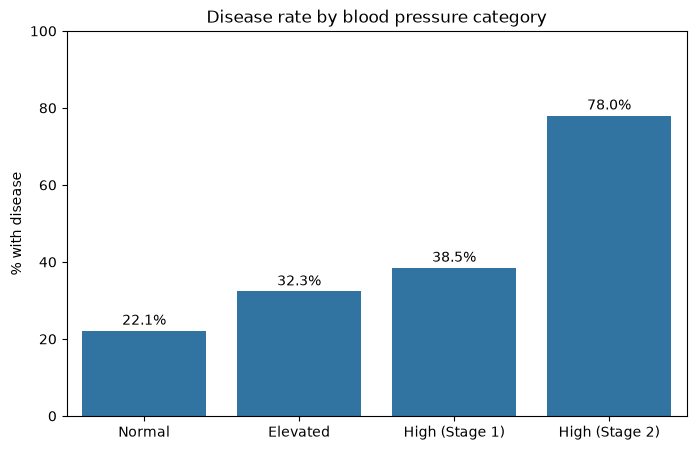

In [47]:
def bp_category(row):
    if row["ap_hi"] >= 140 or row["ap_lo"] >= 90:
        return "High (Stage 2)"
    elif row["ap_hi"] >= 130 or row["ap_lo"] >= 80:
        return "High (Stage 1)"
    elif row["ap_hi"] >= 120:
        return "Elevated"
    return "Normal"

df["bp_group"] = df.apply(bp_category, axis=1)

order = ["Normal", "Elevated", "High (Stage 1)", "High (Stage 2)"]
r = df.groupby("bp_group")["cardio"].mean().mul(100).reindex(order)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=r.index, y=r.values)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2)
plt.title("Disease rate by blood pressure category")
plt.ylabel("% with disease")
plt.xlabel("")
plt.ylim(0, 100)
plt.show()

In [48]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'bmi',
       'gender_label', 'cardio_label', 'chol_label', 'gluc_label', 'age_group',
       'bmi_group', 'age_years', 'bp_group'],
      dtype='str')

In [49]:
df.shape

(68591, 22)

In [50]:
def bp_category(row):
    if row["ap_hi"] >= 140 or row["ap_lo"] >= 90:
        return "High (Stage 2)"
    elif row["ap_hi"] >= 130 or row["ap_lo"] >= 80:
        return "High (Stage 1)"
    elif row["ap_hi"] >= 120:
        return "Elevated"
    return "Normal"

df["bp_group"] = df.apply(bp_category, axis=1)

print(df["bp_group"].value_counts())

bp_group
High (Stage 1)    32428
High (Stage 2)    23514
Normal             9543
Elevated           3106
Name: count, dtype: int64


## 7. Checks after cleaning

Shape, missing values, duplicates and value ranges.

In [51]:
df.shape

(68591, 22)

In [52]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'bmi',
       'gender_label', 'cardio_label', 'chol_label', 'gluc_label', 'age_group',
       'bmi_group', 'age_years', 'bp_group'],
      dtype='str')

In [53]:
print(df.shape)                              # should be (68591, ...)
print(df.isna().sum().sum(), "missing")      # should be 0
print(df.duplicated().sum(), "duplicates")   # should be 0

print(df[["age_group", "height", "weight", "bmi", "ap_hi", "ap_lo"]].describe().round(1))

(68591, 22)
0 missing
0 duplicates
        height   weight      bmi    ap_hi    ap_lo
count  68591.0  68591.0  68591.0  68591.0  68591.0
mean     164.4     74.1     27.4    126.7     81.3
std        7.9     14.2      5.2     16.7      9.5
min      120.0     30.0     12.3     60.0     40.0
25%      159.0     65.0     23.9    120.0     80.0
50%      165.0     72.0     26.3    120.0     80.0
75%      170.0     82.0     30.1    140.0     90.0
max      207.0    200.0     59.5    240.0    182.0


In [54]:
print(df.shape)
print(df.isna().sum().sum(), "missing")
print(df.duplicated().sum(), "duplicates")
print(df[["age_years", "height", "weight", "bmi", "ap_hi", "ap_lo"]].describe().round(1))
print((df["ap_hi"] <= df["ap_lo"]).sum(), "rows where top BP <= bottom BP")

(68591, 22)
0 missing
0 duplicates
       age_years   height   weight      bmi    ap_hi    ap_lo
count    68591.0  68591.0  68591.0  68591.0  68591.0  68591.0
mean        53.3    164.4     74.1     27.4    126.7     81.3
std          6.8      7.9     14.2      5.2     16.7      9.5
min         30.0    120.0     30.0     12.3     60.0     40.0
25%         48.0    159.0     65.0     23.9    120.0     80.0
50%         54.0    165.0     72.0     26.3    120.0     80.0
75%         58.0    170.0     82.0     30.1    140.0     90.0
max         65.0    207.0    200.0     59.5    240.0    182.0
0 rows where top BP <= bottom BP


## 8. Disease rate by factor (charts)

Cholesterol, glucose, age, BMI, smoking and activity, plus who is in the data.

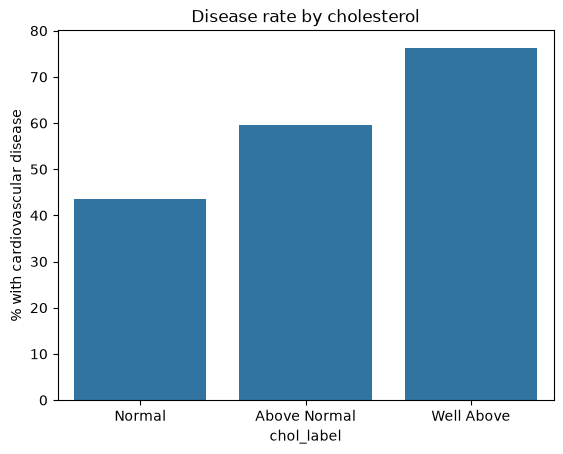

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt

# Disease rate (%) by cholesterol level
rate = df.groupby("chol_label")["cardio"].mean().mul(100).reindex(["Normal", "Above Normal", "Well Above"])
sns.barplot(x=rate.index, y=rate.values)
plt.ylabel("% with cardiovascular disease")
plt.title("Disease rate by cholesterol")
plt.show()

In [56]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'bmi',
       'gender_label', 'cardio_label', 'chol_label', 'gluc_label', 'age_group',
       'bmi_group', 'age_years', 'bp_group'],
      dtype='str')

In [57]:
df.columns.tolist()

['id',
 'age',
 'gender',
 'height',
 'weight',
 'ap_hi',
 'ap_lo',
 'cholesterol',
 'gluc',
 'smoke',
 'alco',
 'active',
 'cardio',
 'bmi',
 'gender_label',
 'cardio_label',
 'chol_label',
 'gluc_label',
 'age_group',
 'bmi_group',
 'age_years',
 'bp_group']

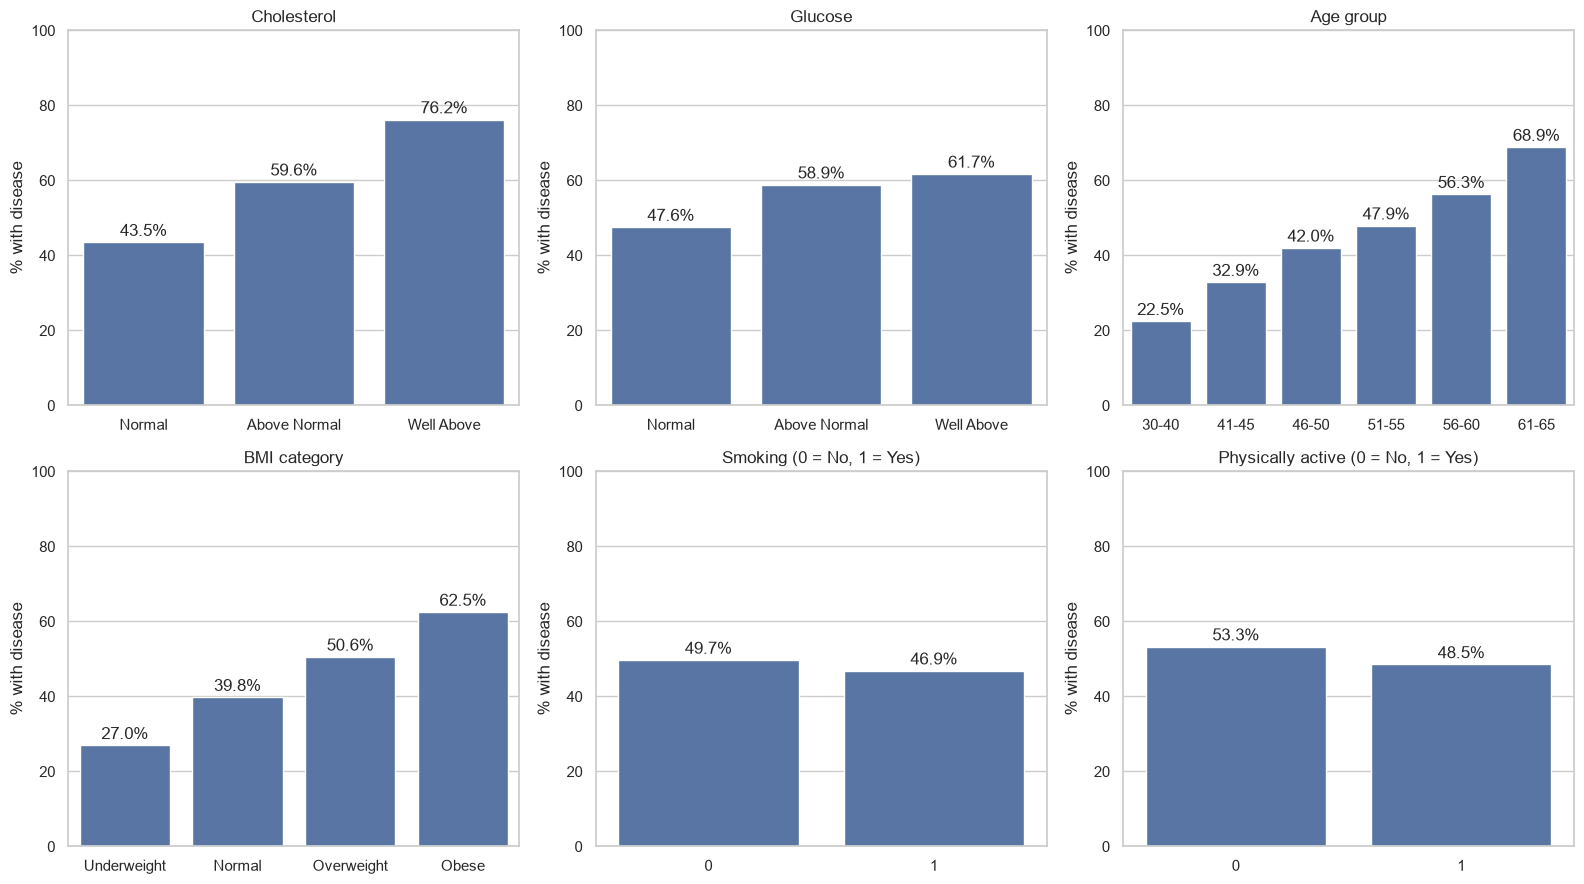

In [58]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

def rate_plot(col, ax, order=None, title=""):
    r = df.groupby(col, observed=True)["cardio"].mean().mul(100)
    if order: r = r.reindex(order)
    sns.barplot(x=r.index.astype(str), y=r.values, ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("% with disease")
    ax.set_ylim(0, 100)

rate_plot("chol_label", axes[0,0], ["Normal","Above Normal","Well Above"], "Cholesterol")
rate_plot("gluc_label", axes[0,1], ["Normal","Above Normal","Well Above"], "Glucose")
rate_plot("age_group", axes[0,2], title="Age group")
rate_plot("bmi_group", axes[1,0], ["Underweight","Normal","Overweight","Obese"], "BMI category")
rate_plot("smoke", axes[1,1], title="Smoking (0 = No, 1 = Yes)")
rate_plot("active", axes[1,2], title="Physically active (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()

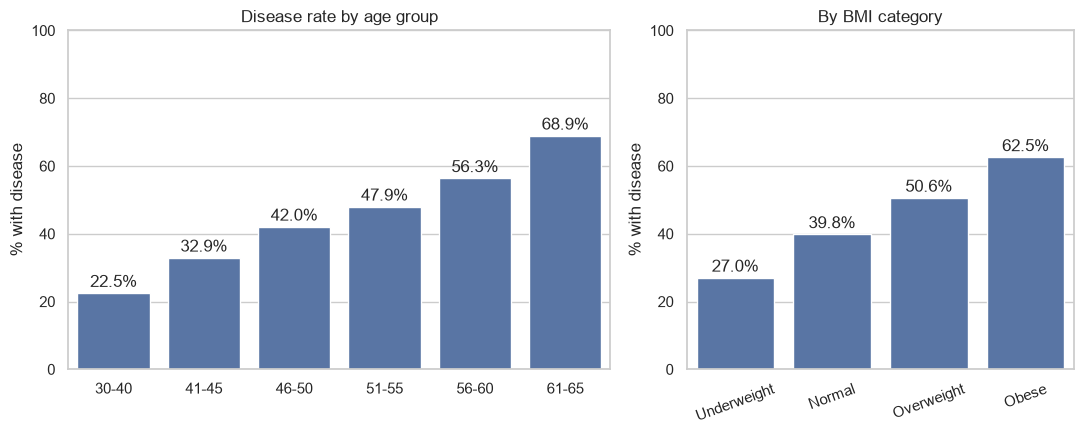

In [59]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})

def rate_plot(col, ax, order, title):
    r = df.groupby(col, observed=True)["cardio"].mean().mul(100).reindex(order)
    sns.barplot(x=r.index.astype(str), y=r.values, ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("% with disease")
    ax.set_ylim(0, 100)

rate_plot("age_group", axes[0], ["30-40", "41-45", "46-50", "51-55", "56-60", "61-65"],
          "Disease rate by age group")
rate_plot("bmi_group", axes[1], ["Underweight", "Normal", "Overweight", "Obese"],
          "By BMI category")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [60]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'bmi',
       'gender_label', 'cardio_label', 'chol_label', 'gluc_label', 'age_group',
       'bmi_group', 'age_years', 'bp_group'],
      dtype='str')

In [61]:
df.shape

(68591, 22)

In [62]:
df["age_group"]

0        46-50
1        51-55
2        51-55
3        46-50
4        46-50
         ...  
69995    51-55
69996    61-65
69997    51-55
69998    61-65
69999    56-60
Name: age_group, Length: 68591, dtype: category
Categories (6, str): ['30-40' < '41-45' < '46-50' < '51-55' < '56-60' < '61-65']

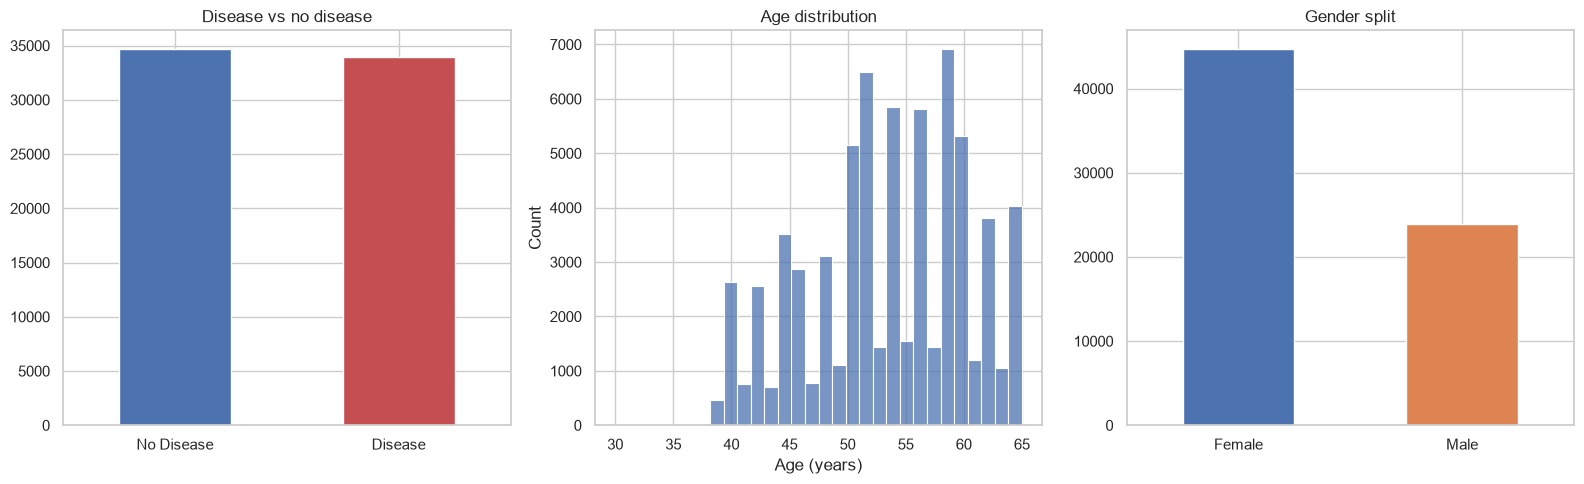

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

df["cardio_label"].value_counts().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#C44E52"])
axes[0].set_title("Disease vs no disease")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)

sns.histplot(df["age_years"], bins=30, ax=axes[1])
axes[1].set_title("Age distribution")
axes[1].set_xlabel("Age (years)")

df["gender_label"].value_counts().plot(kind="bar", ax=axes[2], color=["#4C72B0", "#DD8452"])
axes[2].set_title("Gender split")
axes[2].set_xlabel("")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [64]:
df.shape

(68591, 22)

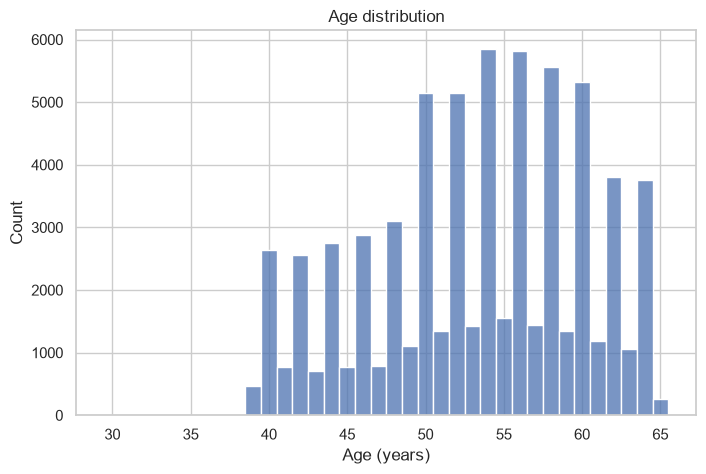

In [65]:
plt.figure(figsize=(8, 5))
sns.histplot(df["age_years"], discrete=True)
plt.title("Age distribution")
plt.xlabel("Age (years)")
plt.show()

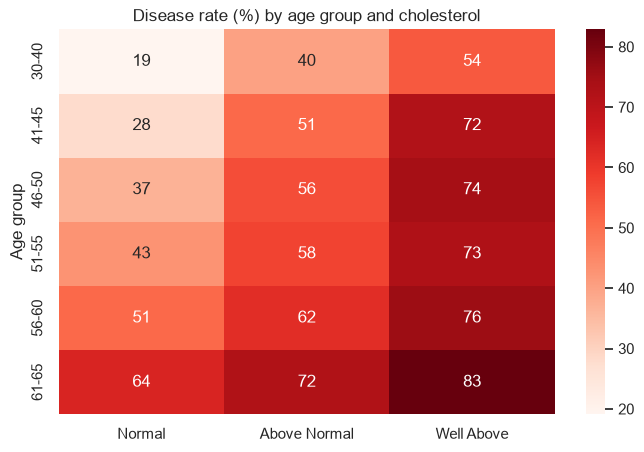

In [66]:
pivot = df.pivot_table(index="age_group", columns="chol_label",
                       values="cardio", aggfunc="mean", observed=True).mul(100)
pivot = pivot[["Normal", "Above Normal", "Well Above"]]

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Reds")
plt.title("Disease rate (%) by age group and cholesterol")
plt.ylabel("Age group")
plt.xlabel("")
plt.show()

## 9. Correlation

Heatmap and ranking of every factor against heart disease.

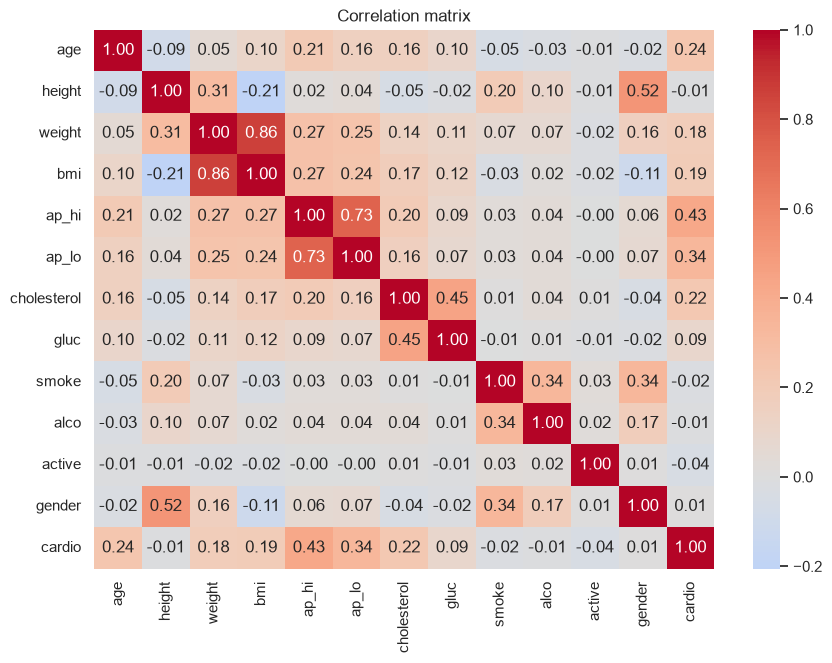

In [67]:
import seaborn as sns
import matplotlib.pyplot as plt

num_cols = ["age", "height", "weight", "bmi", "ap_hi", "ap_lo",
            "cholesterol", "gluc", "smoke", "alco", "active", "gender", "cardio"]

plt.figure(figsize=(10, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

In [68]:
corr = df[num_cols].corr()["cardio"].drop("cardio").sort_values(ascending=False)
print(corr.round(2))

ap_hi          0.43
ap_lo          0.34
age            0.24
cholesterol    0.22
bmi            0.19
weight         0.18
gluc           0.09
gender         0.01
alco          -0.01
height        -0.01
smoke         -0.02
active        -0.04
Name: cardio, dtype: float64


In [69]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'bmi',
       'gender_label', 'cardio_label', 'chol_label', 'gluc_label', 'age_group',
       'bmi_group', 'age_years', 'bp_group'],
      dtype='str')

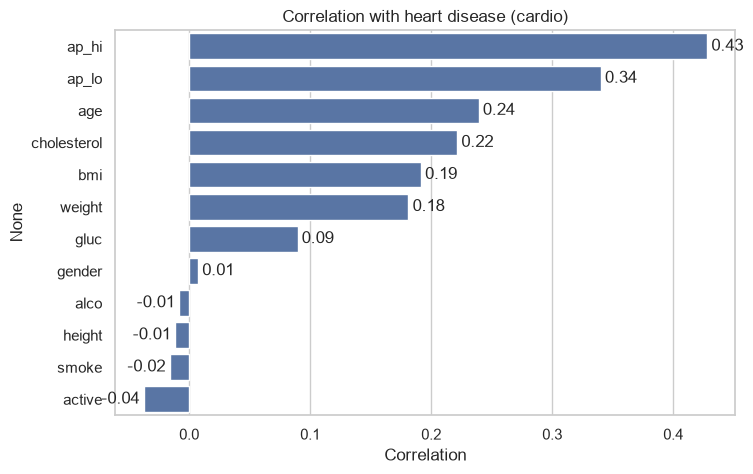

In [70]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=corr.values, y=corr.index, color="#4C72B0")
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.title("Correlation with heart disease (cardio)")
plt.xlabel("Correlation")
plt.show()

## 10. Smoking and alcohol

Disease rate by gender and habit, and who smokes or drinks.

In [71]:
print(df.groupby("smoke")[["age", "bmi"]].median())

        age        bmi
smoke                 
0      54.0  26.365603
1      52.0  26.171875


In [72]:
df.groupby("gender")[["smoke","cardio"]].value_counts()

gender  smoke  cardio
1       0      0         22274
               1         21609
        1      0           421
               1           372
2       0      1          9495
               0          9179
        1      0          2786
               1          2455
Name: count, dtype: int64

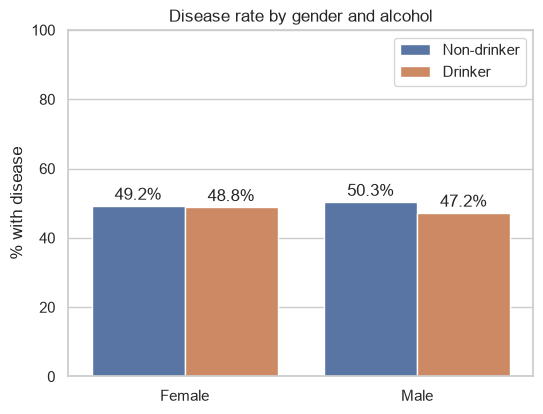

np.float64(0.49385077890133916)

In [73]:
# 1. Drinkers vs non-drinkers: disease rate (%)
df.groupby("alco")["cardio"].mean().mul(100).round(1)

# 2. How many drink
df["alco"].value_counts()

# 3. Chart: disease rate by gender and alcohol
rate = (df.groupby(["gender_label", "alco"])["cardio"]
        
          .mean().mul(100).round(1).reset_index())
rate["Alcohol"] = rate["alco"].map({0: "Non-drinker", 1: "Drinker"})

plt.figure(figsize=(6, 4.5))
ax = sns.barplot(data=rate, x="gender_label", y="cardio",
                 hue="Alcohol", order=["Female", "Male"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=2)
plt.title("Disease rate by gender and alcohol")
plt.ylabel("% with disease")
plt.xlabel("")
plt.ylim(0, 100)
plt.legend(title="")
plt.show()

# 4. Who drinks?
df[df["alco"] == 1]["gender"].eq(2).mean()    # share of drinkers who are men
df[df["alco"] == 1]["smoke"].mean()           # share of drinkers who also smoke

## 11. Summary views

Quick looks at the finished dataframe.

In [74]:
df["age_group"]

0        46-50
1        51-55
2        51-55
3        46-50
4        46-50
         ...  
69995    51-55
69996    61-65
69997    51-55
69998    61-65
69999    56-60
Name: age_group, Length: 68591, dtype: category
Categories (6, str): ['30-40' < '41-45' < '46-50' < '51-55' < '56-60' < '61-65']

In [75]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'bmi',
       'gender_label', 'cardio_label', 'chol_label', 'gluc_label', 'age_group',
       'bmi_group', 'age_years', 'bp_group'],
      dtype='str')

In [76]:
df["gender_label"]

0          Male
1        Female
2        Female
3          Male
4        Female
          ...  
69995      Male
69996    Female
69997      Male
69998    Female
69999    Female
Name: gender_label, Length: 68591, dtype: str

In [77]:
df["cardio_label"]

0        No Disease
1           Disease
2           Disease
3           Disease
4        No Disease
            ...    
69995    No Disease
69996       Disease
69997       Disease
69998       Disease
69999    No Disease
Name: cardio_label, Length: 68591, dtype: str

In [78]:
df.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,bmi,age_years
count,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000
mean,49975.548862,53.291685,1.348661,164.417358,74.088873,126.671881,81.306483,1.364785,1.225846,0.087971,0.053345,0.803298,0.494686,27.444328,53.291685
std,28845.183339,6.762097,0.476550,7.904617,14.210972,16.688797,9.453089,0.678988,0.571705,0.283254,0.224723,0.397508,0.499975,5.198104,6.762097
min,0.000000,30.000000,1.000000,120.000000,30.000000,60.000000,40.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,12.254473,30.000000
25%,25004.500000,48.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,23.875115,48.000000
50%,50017.000000,54.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,26.346494,54.000000
75%,74869.500000,58.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000,30.116213,58.000000
max,99999.000000,65.000000,2.000000,207.000000,200.000000,240.000000,182.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000,59.523810,65.000000


In [79]:
df.info()

<class 'pandas.DataFrame'>
Index: 68591 entries, 0 to 69999
Data columns (total 22 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   id            68591 non-null  int64   
 1   age           68591 non-null  int64   
 2   gender        68591 non-null  int64   
 3   height        68591 non-null  int64   
 4   weight        68591 non-null  float64 
 5   ap_hi         68591 non-null  int64   
 6   ap_lo         68591 non-null  int64   
 7   cholesterol   68591 non-null  int64   
 8   gluc          68591 non-null  int64   
 9   smoke         68591 non-null  int64   
 10  alco          68591 non-null  int64   
 11  active        68591 non-null  int64   
 12  cardio        68591 non-null  int64   
 13  bmi           68591 non-null  float64 
 14  gender_label  68591 non-null  str     
 15  cardio_label  68591 non-null  str     
 16  chol_label    68591 non-null  str     
 17  gluc_label    68591 non-null  str     
 18  age_group     68591 no

In [80]:
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,...,cardio,bmi,gender_label,cardio_label,chol_label,gluc_label,age_group,bmi_group,age_years,bp_group
0,0,50,2,168,62.0,110,80,1,1,0,...,0,21.967120,Male,No Disease,Normal,Normal,46-50,Normal,50,High (Stage 1)
1,1,55,1,156,85.0,140,90,3,1,0,...,1,34.927679,Female,Disease,Well Above,Normal,51-55,Obese,55,High (Stage 2)
2,2,52,1,165,64.0,130,70,3,1,0,...,1,23.507805,Female,Disease,Well Above,Normal,51-55,Normal,52,High (Stage 1)
3,3,48,2,169,82.0,150,100,1,1,0,...,1,28.710479,Male,Disease,Normal,Normal,46-50,Overweight,48,High (Stage 2)
4,4,48,1,156,56.0,100,60,1,1,0,...,0,23.011177,Female,No Disease,Normal,Normal,46-50,Normal,48,Normal


In [81]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'bmi',
       'gender_label', 'cardio_label', 'chol_label', 'gluc_label', 'age_group',
       'bmi_group', 'age_years', 'bp_group'],
      dtype='str')

In [82]:
df.shape

(68591, 22)

In [83]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'bmi',
       'gender_label', 'cardio_label', 'chol_label', 'gluc_label', 'age_group',
       'bmi_group', 'age_years', 'bp_group'],
      dtype='str')

## 12. Rebuild the whole pipeline in one cell

Load, clean and create every new column in a single cell, then check it.

In [84]:
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt

df = pd.read_csv("cardio_train.csv", sep=",")
df["bmi"] = df["weight"] / (df["height"] / 100) ** 2

# Cleaning
df = df[
    df["ap_hi"].between(60, 250) &
    df["ap_lo"].between(40, 200) &
    (df["ap_hi"] > df["ap_lo"]) &
    df["height"].between(120, 220) &
    df["weight"].between(30, 200) &
    df["bmi"].between(12, 60)
].copy()

# Labels and groups (age is kept, only id is dropped)
df = df.drop(columns=["id"])
df["gender_label"] = df["gender"].map({1: "Female", 2: "Male"})
df["cardio_label"] = df["cardio"].map({0: "No Disease", 1: "Disease"})
df["chol_label"] = df["cholesterol"].map({1: "Normal", 2: "Above Normal", 3: "Well Above"})
df["gluc_label"] = df["gluc"].map({1: "Normal", 2: "Above Normal", 3: "Well Above"})
df["age_group"] = pd.cut(df["age"], bins=[29, 40, 45, 50, 55, 60, 65],
                         labels=["30-40", "41-45", "46-50", "51-55", "56-60", "61-65"])
df["bmi_group"] = pd.cut(df["bmi"], bins=[0, 18.5, 25, 30, 100],
                         labels=["Underweight", "Normal", "Overweight", "Obese"])

def bp_category(row):
    if row["ap_hi"] >= 140 or row["ap_lo"] >= 90: return "High (Stage 2)"
    if row["ap_hi"] >= 130 or row["ap_lo"] >= 80: return "High (Stage 1)"
    if row["ap_hi"] >= 120: return "Elevated"
    return "Normal"
df["bp_group"] = df.apply(bp_category, axis=1)

print(df.shape)                    # (68591, 19)
print(df.columns.tolist())         # 'age' should be in the list

(68591, 20)
['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'bmi', 'gender_label', 'cardio_label', 'chol_label', 'gluc_label', 'age_group', 'bmi_group', 'bp_group']


In [85]:
df["age_group"] = pd.cut(df["age"], bins=[29, 40, 45, 50, 55, 60, 65],
                            labels=["30-40", "41-45", "46-50", "51-55", "56-60", "61-65"])


In [86]:
import pandas as pd

orig = pd.read_csv("cardio_train.csv", sep=",")
df["age"] = orig.loc[df.index, "age"].astype(int)

print(df["age"].describe())
print((orig.loc[df.index, "height"] == df["height"]).all())

count    68591.000000
mean        53.291685
std          6.762097
min         30.000000
25%         48.000000
50%         54.000000
75%         58.000000
max         65.000000
Name: age, dtype: float64
True


In [87]:
df.shape

(68591, 20)

In [88]:
df.columns

Index(['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol',
       'gluc', 'smoke', 'alco', 'active', 'cardio', 'bmi', 'gender_label',
       'cardio_label', 'chol_label', 'gluc_label', 'age_group', 'bmi_group',
       'bp_group'],
      dtype='str')

In [89]:
df.columns

Index(['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol',
       'gluc', 'smoke', 'alco', 'active', 'cardio', 'bmi', 'gender_label',
       'cardio_label', 'chol_label', 'gluc_label', 'age_group', 'bmi_group',
       'bp_group'],
      dtype='str')

In [90]:
df.shape

(68591, 20)

In [91]:
print("age" in df.columns)

True


In [92]:
print("age" in df.columns)
df["age_group"].value_counts().sort_index()

True


age_group
30-40     3107
41-45     7554
46-50    13015
51-55    15343
56-60    19489
61-65    10083
Name: count, dtype: int64

In [93]:
df.columns

Index(['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol',
       'gluc', 'smoke', 'alco', 'active', 'cardio', 'bmi', 'gender_label',
       'cardio_label', 'chol_label', 'gluc_label', 'age_group', 'bmi_group',
       'bp_group'],
      dtype='str')

## 13. Save and reload the cleaned dataset

Save cardio_clean.csv first, then read it back and check it.

In [94]:
df.to_csv("cardio_clean.csv", index=False)

In [95]:
import pandas as pd
df= pd.read_csv("cardio_clean.csv")
df.shape       

(68591, 20)

In [96]:
df.isnull().sum()

age             0
gender          0
height          0
weight          0
ap_hi           0
ap_lo           0
cholesterol     0
gluc            0
smoke           0
alco            0
active          0
cardio          0
bmi             0
gender_label    0
cardio_label    0
chol_label      0
gluc_label      0
age_group       0
bmi_group       0
bp_group        0
dtype: int64

In [97]:
df = df.drop(columns=["id"], errors="ignore")
df["bmi"] = df["weight"] / (df["height"] / 100) ** 2

df["gender_label"] = df["gender"].map({1: "Female", 2: "Male"})
df["cardio_label"] = df["cardio"].map({0: "No Disease", 1: "Disease"})
df["chol_label"] = df["cholesterol"].map({1: "Normal", 2: "Above Normal", 3: "Well Above"})
df["gluc_label"] = df["gluc"].map({1: "Normal", 2: "Above Normal", 3: "Well Above"})

df["age_group"] = pd.cut(df["age"], bins=[29, 40, 45, 50, 55, 60, 65],
                         labels=["30-40", "41-45", "46-50", "51-55", "56-60", "61-65"])
df["bmi_group"] = pd.cut(df["bmi"], bins=[0, 18.5, 25, 30, 100],
                         labels=["Underweight", "Normal", "Overweight", "Obese"], right=False)

def bp_category(row):
    if row["ap_hi"] >= 140 or row["ap_lo"] >= 90: return "High (Stage 2)"
    elif row["ap_hi"] >= 130 or row["ap_lo"] >= 80: return "High (Stage 1)"
    elif row["ap_hi"] >= 120: return "Elevated"
    return "Normal"
df["bp_group"] = df.apply(bp_category, axis=1)

df.to_csv("cardio_clean.csv", index=False)

print(df.shape)              # (68591, 20)
print(df.columns.tolist())   

(68591, 20)
['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'bmi', 'gender_label', 'cardio_label', 'chol_label', 'gluc_label', 'age_group', 'bmi_group', 'bp_group']


In [98]:
df.describe

<bound method NDFrame.describe of        age  gender  height  weight  ap_hi  ap_lo  cholesterol  gluc  smoke  \
0       50       2     168    62.0    110     80            1     1      0   
1       55       1     156    85.0    140     90            3     1      0   
2       52       1     165    64.0    130     70            3     1      0   
3       48       2     169    82.0    150    100            1     1      0   
4       48       1     156    56.0    100     60            1     1      0   
...    ...     ...     ...     ...    ...    ...          ...   ...    ...   
68586   53       2     168    76.0    120     80            1     1      1   
68587   62       1     158   126.0    140     90            2     2      0   
68588   52       2     183   105.0    180     90            3     1      0   
68589   61       1     163    72.0    135     80            1     2      0   
68590   56       1     170    72.0    120     80            2     1      0   

       alco  active  cardio  

In [99]:
import pandas as pd
check = pd.read_csv("cardio_clean.csv")
print(check.shape)    

(68591, 20)


In [100]:
df.isnull()

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,bmi,gender_label,cardio_label,chol_label,gluc_label,age_group,bmi_group,bp_group
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68586,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
68587,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
68588,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
68589,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [101]:
df.describe()

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,bmi
count,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000
mean,53.291685,1.348661,164.417358,74.088873,126.671881,81.306483,1.364785,1.225846,0.087971,0.053345,0.803298,0.494686,27.444328
std,6.762097,0.476550,7.904617,14.210972,16.688797,9.453089,0.678988,0.571705,0.283254,0.224723,0.397508,0.499975,5.198104
min,30.000000,1.000000,120.000000,30.000000,60.000000,40.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,12.254473
25%,48.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,23.875115
50%,54.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,26.346494
75%,58.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000,30.116213
max,65.000000,2.000000,207.000000,200.000000,240.000000,182.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000,59.523810


In [102]:
df.describe(include="all")

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,bmi,gender_label,cardio_label,chol_label,gluc_label,age_group,bmi_group,bp_group
count,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591,68591,68591,68591,68591,68591,68591
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2,3,3,6,4,4
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Female,No Disease,Normal,Normal,56-60,Normal,High (Stage 1)
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,44676,34660,51434,58313,19489,25425,32428
mean,53.291685,1.348661,164.417358,74.088873,126.671881,81.306483,1.364785,1.225846,0.087971,0.053345,0.803298,0.494686,27.444328,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,6.762097,0.476550,7.904617,14.210972,16.688797,9.453089,0.678988,0.571705,0.283254,0.224723,0.397508,0.499975,5.198104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,30.000000,1.000000,120.000000,30.000000,60.000000,40.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,12.254473,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,48.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,23.875115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,54.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,26.346494,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,58.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000,30.116213,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [103]:
pd.set_option("display.max_columns", None)
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,68591.0,NaN,NaN,NaN,53.291685,6.762097,30.0,48.0,54.0,58.0,65.0
gender,68591.0,NaN,NaN,NaN,1.348661,0.47655,1.0,1.0,1.0,2.0,2.0
height,68591.0,NaN,NaN,NaN,164.417358,7.904617,120.0,159.0,165.0,170.0,207.0
weight,68591.0,NaN,NaN,NaN,74.088873,14.210972,30.0,65.0,72.0,82.0,200.0
ap_hi,68591.0,NaN,NaN,NaN,126.671881,16.688797,60.0,120.0,120.0,140.0,240.0
ap_lo,68591.0,NaN,NaN,NaN,81.306483,9.453089,40.0,80.0,80.0,90.0,182.0
cholesterol,68591.0,NaN,NaN,NaN,1.364785,0.678988,1.0,1.0,1.0,2.0,3.0
gluc,68591.0,NaN,NaN,NaN,1.225846,0.571705,1.0,1.0,1.0,1.0,3.0
smoke,68591.0,NaN,NaN,NaN,0.087971,0.283254,0.0,0.0,0.0,0.0,1.0
alco,68591.0,NaN,NaN,NaN,0.053345,0.224723,0.0,0.0,0.0,0.0,1.0


In [104]:
df = pd.read_csv("cardio_clean.csv")

df = df[
    df["ap_hi"].between(60, 250) &
    df["ap_lo"].between(40, 200) &
    (df["ap_hi"] > df["ap_lo"]) &
    df["height"].between(120, 220) &
    df["weight"].between(30, 200) &
    df["bmi"].between(12, 60)
].copy()

df.to_csv("cardio_clean.csv", index=False)
print(df.shape)       
df.describe(include="all").T

(68591, 20)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,68591.0,NaN,NaN,NaN,53.291685,6.762097,30.0,48.0,54.0,58.0,65.0
gender,68591.0,NaN,NaN,NaN,1.348661,0.47655,1.0,1.0,1.0,2.0,2.0
height,68591.0,NaN,NaN,NaN,164.417358,7.904617,120.0,159.0,165.0,170.0,207.0
weight,68591.0,NaN,NaN,NaN,74.088873,14.210972,30.0,65.0,72.0,82.0,200.0
ap_hi,68591.0,NaN,NaN,NaN,126.671881,16.688797,60.0,120.0,120.0,140.0,240.0
ap_lo,68591.0,NaN,NaN,NaN,81.306483,9.453089,40.0,80.0,80.0,90.0,182.0
cholesterol,68591.0,NaN,NaN,NaN,1.364785,0.678988,1.0,1.0,1.0,2.0,3.0
gluc,68591.0,NaN,NaN,NaN,1.225846,0.571705,1.0,1.0,1.0,1.0,3.0
smoke,68591.0,NaN,NaN,NaN,0.087971,0.283254,0.0,0.0,0.0,0.0,1.0
alco,68591.0,NaN,NaN,NaN,0.053345,0.224723,0.0,0.0,0.0,0.0,1.0


In [105]:
df.describe()

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,bmi
count,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000
mean,53.291685,1.348661,164.417358,74.088873,126.671881,81.306483,1.364785,1.225846,0.087971,0.053345,0.803298,0.494686,27.444328
std,6.762097,0.476550,7.904617,14.210972,16.688797,9.453089,0.678988,0.571705,0.283254,0.224723,0.397508,0.499975,5.198104
min,30.000000,1.000000,120.000000,30.000000,60.000000,40.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,12.254473
25%,48.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,23.875115
50%,54.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,26.346494
75%,58.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000,30.116213
max,65.000000,2.000000,207.000000,200.000000,240.000000,182.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000,59.523810


In [106]:
pd.set_option("display.max_columns", None)
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,68591.0,NaN,NaN,NaN,53.291685,6.762097,30.0,48.0,54.0,58.0,65.0
gender,68591.0,NaN,NaN,NaN,1.348661,0.47655,1.0,1.0,1.0,2.0,2.0
height,68591.0,NaN,NaN,NaN,164.417358,7.904617,120.0,159.0,165.0,170.0,207.0
weight,68591.0,NaN,NaN,NaN,74.088873,14.210972,30.0,65.0,72.0,82.0,200.0
ap_hi,68591.0,NaN,NaN,NaN,126.671881,16.688797,60.0,120.0,120.0,140.0,240.0
ap_lo,68591.0,NaN,NaN,NaN,81.306483,9.453089,40.0,80.0,80.0,90.0,182.0
cholesterol,68591.0,NaN,NaN,NaN,1.364785,0.678988,1.0,1.0,1.0,2.0,3.0
gluc,68591.0,NaN,NaN,NaN,1.225846,0.571705,1.0,1.0,1.0,1.0,3.0
smoke,68591.0,NaN,NaN,NaN,0.087971,0.283254,0.0,0.0,0.0,0.0,1.0
alco,68591.0,NaN,NaN,NaN,0.053345,0.224723,0.0,0.0,0.0,0.0,1.0


In [107]:
df.describe(include="all")

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,bmi,gender_label,cardio_label,chol_label,gluc_label,age_group,bmi_group,bp_group
count,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591.000000,68591,68591,68591,68591,68591,68591,68591
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2,3,3,6,4,4
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Female,No Disease,Normal,Normal,56-60,Normal,High (Stage 1)
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,44676,34660,51434,58313,19489,25425,32428
mean,53.291685,1.348661,164.417358,74.088873,126.671881,81.306483,1.364785,1.225846,0.087971,0.053345,0.803298,0.494686,27.444328,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,6.762097,0.476550,7.904617,14.210972,16.688797,9.453089,0.678988,0.571705,0.283254,0.224723,0.397508,0.499975,5.198104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,30.000000,1.000000,120.000000,30.000000,60.000000,40.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,12.254473,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,48.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,23.875115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,54.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,26.346494,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,58.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000,30.116213,NaN,NaN,NaN,NaN,NaN,NaN,NaN


---

# Part 2: Clean short version

The same analysis written once, in order, with no repeated cells. It reloads the data from `cardio_train.csv`, so it can also be run on its own.

## 1. Load and inspect

Load the file and check its size, missing values and duplicates. `id` makes every row unique, so duplicates show 0 here.

In [108]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

df = pd.read_csv("cardio_train.csv")
print(df.shape)                                  # (70000, 13)
print(df.isnull().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicates")
df["cardio"].value_counts(normalize=True).round(3)   # about 50% / 50%

(70000, 13)
0 missing values
0 duplicates


cardio
0    0.5
1    0.5
Name: proportion, dtype: float64

## 2. Cleaning

Calculate BMI, then keep only rows where every value is possible. Rows that fail any rule are removed (impossible blood pressure, height, weight or BMI). `id` is dropped because it is only a row number.

In [109]:
df["bmi"] = df["weight"] / (df["height"] / 100) ** 2

before = len(df)
df = df[
    df["ap_hi"].between(60, 250) &
    df["ap_lo"].between(40, 200) &
    (df["ap_hi"] > df["ap_lo"]) &
    df["height"].between(120, 220) &
    df["weight"].between(30, 200) &
    df["bmi"].between(12, 60)
].copy()
print(f"Removed {before - len(df)} rows ({(before - len(df)) / before:.1%})")

df = df.drop(columns=["id"])
df.shape                                         # (68591, 13)

Removed 1409 rows (2.0%)


(68591, 13)

## 3. New columns

`map()` turns codes (1, 2, 3) into words. `pd.cut()` sorts a number into groups. The blood pressure group uses the higher category of the two numbers.

In [110]:
df["gender_label"] = df["gender"].map({1: "Female", 2: "Male"})
df["cardio_label"] = df["cardio"].map({0: "No Disease", 1: "Disease"})
df["chol_label"] = df["cholesterol"].map({1: "Normal", 2: "Above Normal", 3: "Well Above"})
df["gluc_label"] = df["gluc"].map({1: "Normal", 2: "Above Normal", 3: "Well Above"})

df["age_group"] = pd.cut(df["age"], bins=[29, 40, 45, 50, 55, 60, 65],
                         labels=["30-40", "41-45", "46-50", "51-55", "56-60", "61-65"])
df["bmi_group"] = pd.cut(df["bmi"], bins=[0, 18.5, 25, 30, 100],
                         labels=["Underweight", "Normal", "Overweight", "Obese"], right=False)

def bp_category(row):
    if row["ap_hi"] >= 140 or row["ap_lo"] >= 90:
        return "High (Stage 2)"
    elif row["ap_hi"] >= 130 or row["ap_lo"] >= 80:
        return "High (Stage 1)"
    elif row["ap_hi"] >= 120:
        return "Elevated"
    return "Normal"

df["bp_group"] = df.apply(bp_category, axis=1)
df.shape                                         # (68591, 20)

(68591, 20)

### Check after cleaning

No missing values. The 3,820 duplicates appear only after `id` is dropped. They are different patients with the same values (age is in whole years and most columns have few values), so they are kept.

In [111]:
print(df.shape)
print(df.isnull().sum().sum(), "missing")
print(df.duplicated().sum(), "duplicates (different patients, kept)")
df[["age", "height", "weight", "bmi", "ap_hi", "ap_lo"]].describe().round(1)

(68591, 20)
0 missing
3820 duplicates (different patients, kept)


,age,height,weight,bmi,ap_hi,ap_lo
count,68591.0,68591.0,68591.0,68591.0,68591.0,68591.0
mean,53.3,164.4,74.1,27.4,126.7,81.3
std,6.8,7.9,14.2,5.2,16.7,9.5
min,30.0,120.0,30.0,12.3,60.0,40.0
25%,48.0,159.0,65.0,23.9,120.0,80.0
50%,54.0,165.0,72.0,26.3,120.0,80.0
75%,58.0,170.0,82.0,30.1,140.0,90.0
max,65.0,207.0,200.0,59.5,240.0,182.0


## 4. Disease rate by factor

The average of `cardio` (0 or 1) in a group is the share of that group with disease. Rates are used instead of counts because groups differ in size. One helper function draws every bar chart.

In [112]:
def rate_bar(col, order, title, ax=None):
    rate = df.groupby(col, observed=True)["cardio"].mean().mul(100).reindex(order)
    ax = sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("% with disease")
    ax.set_ylim(0, 100)
    return ax

### Blood pressure (22.1% to 78.0%)

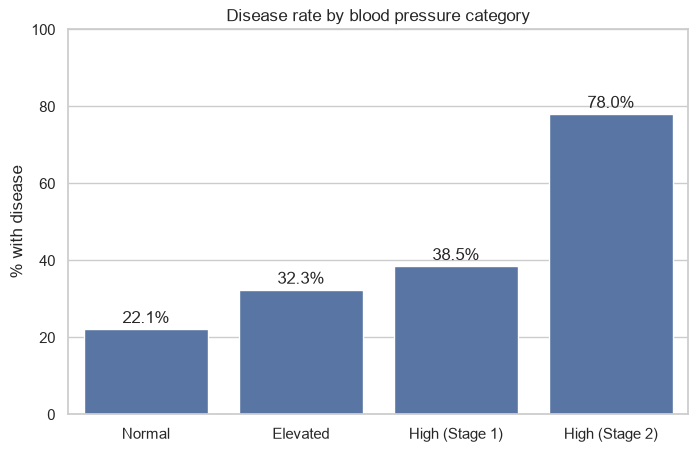

In [113]:
plt.figure(figsize=(8, 5))
rate_bar("bp_group", ["Normal", "Elevated", "High (Stage 1)", "High (Stage 2)"],
         "Disease rate by blood pressure category")
plt.show()

### Cholesterol (43.5% to 76.2%)

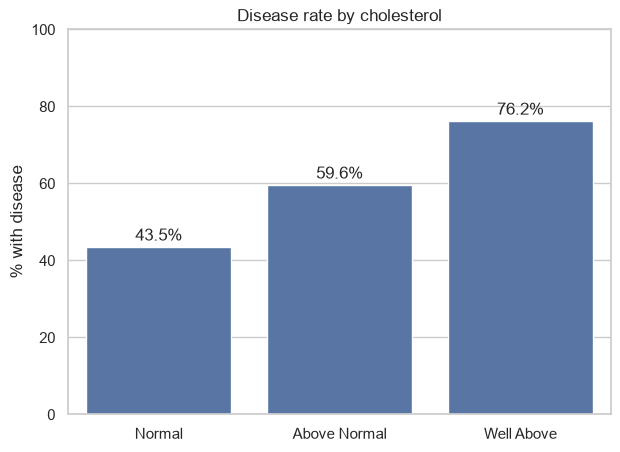

In [114]:
plt.figure(figsize=(7, 5))
rate_bar("chol_label", ["Normal", "Above Normal", "Well Above"], "Disease rate by cholesterol")
plt.show()

### Age and BMI

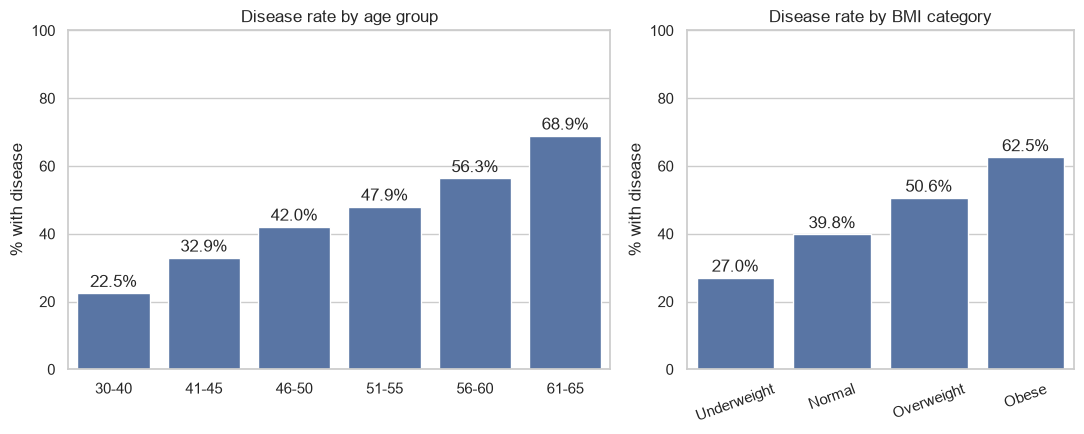

In [115]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
rate_bar("age_group", ["30-40", "41-45", "46-50", "51-55", "56-60", "61-65"],
         "Disease rate by age group", axes[0])
rate_bar("bmi_group", ["Underweight", "Normal", "Overweight", "Obese"],
         "Disease rate by BMI category", axes[1])
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 5. Correlation

`corr()` measures how strongly two number columns move together, from -1 to +1. Only number columns can be used. Look at the `cardio` row. Correlation shows a link, not a cause.

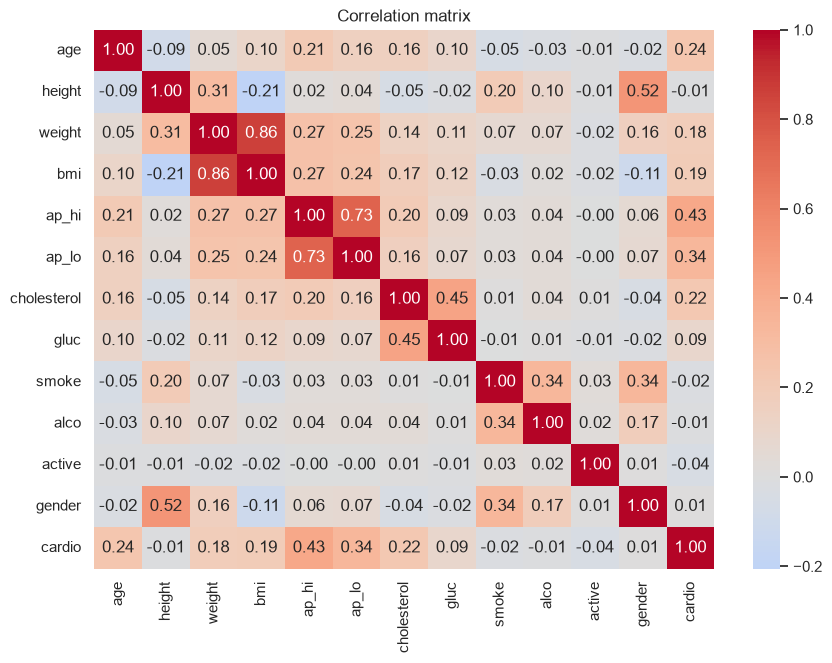

In [116]:
num_cols = ["age", "height", "weight", "bmi", "ap_hi", "ap_lo",
            "cholesterol", "gluc", "smoke", "alco", "active", "gender", "cardio"]

plt.figure(figsize=(10, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

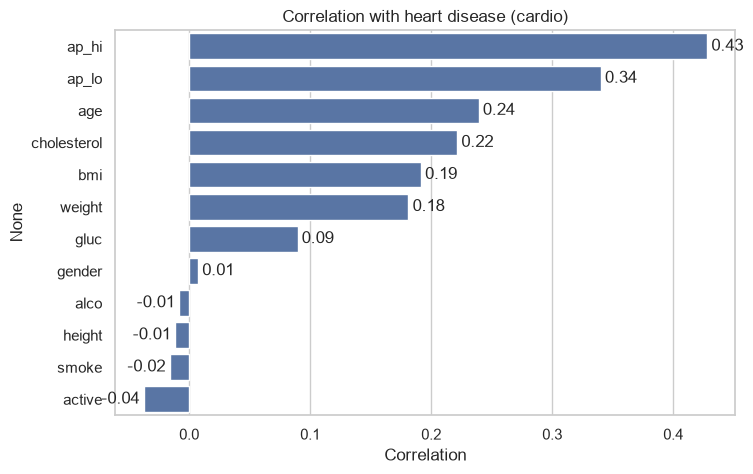

In [117]:
corr = df[num_cols].corr()["cardio"].drop("cardio").sort_values(ascending=False)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=corr.values, y=corr.index, color="#4C72B0")
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.title("Correlation with heart disease (cardio)")
plt.xlabel("Correlation")
plt.show()

## 6. Combined risk: age and cholesterol

`pivot_table` works like `groupby` with two keys: rows are age groups, columns are cholesterol levels.

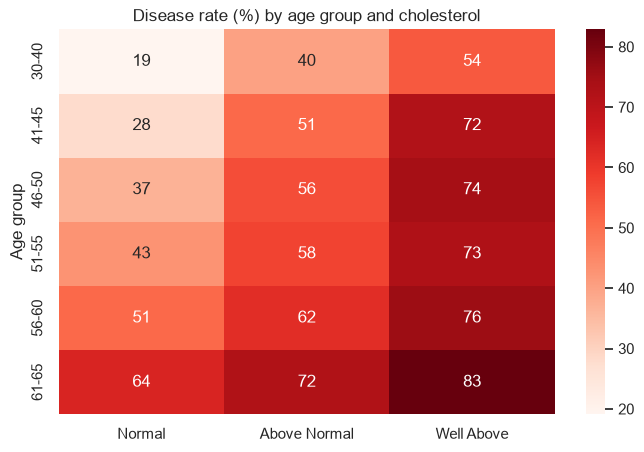

In [118]:
pivot = df.pivot_table(index="age_group", columns="chol_label", values="cardio",
                       aggfunc="mean", observed=True).mul(100)
pivot = pivot[["Normal", "Above Normal", "Well Above"]]

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Reds")
plt.title("Disease rate (%) by age group and cholesterol")
plt.ylabel("Age group")
plt.xlabel("")
plt.show()

## 7. Smoking and alcohol

Both show no higher disease rate. These answers are self-reported, and drinkers and smokers are mostly men, so gender and age are checked.

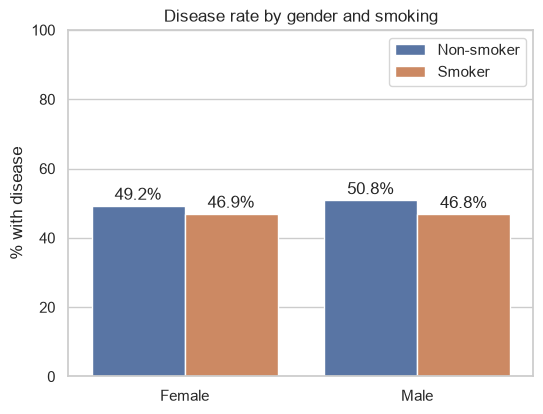

smoke
0    54.0
1    52.0
Name: age, dtype: float64
0.8685780576731853


In [119]:
rate = (df.groupby(["gender_label", "smoke"])["cardio"]
          .mean().mul(100).round(1).reset_index())
rate["Smoking"] = rate["smoke"].map({0: "Non-smoker", 1: "Smoker"})

plt.figure(figsize=(6, 4.5))
ax = sns.barplot(data=rate, x="gender_label", y="cardio", hue="Smoking", order=["Female", "Male"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=2)
plt.title("Disease rate by gender and smoking")
plt.ylabel("% with disease")
plt.xlabel("")
plt.ylim(0, 100)
plt.legend(title="")
plt.show()

print(df.groupby("smoke")["age"].median())              # smokers are younger: 52 vs 54
print(df[df["smoke"] == 1]["gender"].eq(2).mean())      # share of smokers who are men

alco
0    49.6
1    47.7
Name: cardio, dtype: float64
alco
0    64932
1     3659
Name: count, dtype: int64


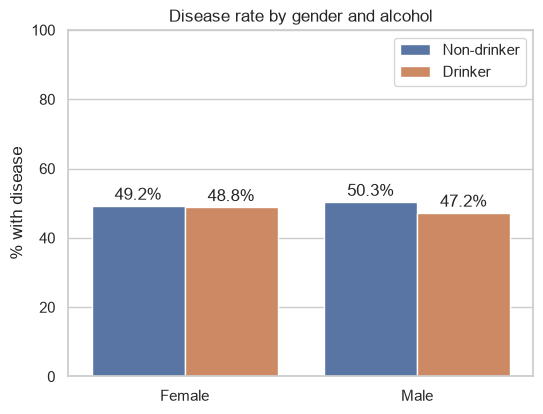

In [120]:
print(df.groupby("alco")["cardio"].mean().mul(100).round(1))   # 49.6 vs 47.7
print(df["alco"].value_counts())                                 # only about 5% drink

rate = (df.groupby(["gender_label", "alco"])["cardio"]
          .mean().mul(100).round(1).reset_index())
rate["Alcohol"] = rate["alco"].map({0: "Non-drinker", 1: "Drinker"})

plt.figure(figsize=(6, 4.5))
ax = sns.barplot(data=rate, x="gender_label", y="cardio", hue="Alcohol", order=["Female", "Male"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=2)
plt.title("Disease rate by gender and alcohol")
plt.ylabel("% with disease")
plt.xlabel("")
plt.ylim(0, 100)
plt.legend(title="")
plt.show()

In [121]:
df.to_csv("cardio_clean.csv", index=False)
print(df.shape)            # (68591, 20)

(68591, 20)
